In [5]:
from collections import Counter
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report
from sklearn.model_selection import GridSearchCV , train_test_split
from sklearn.neighbors import KNeighborsClassifier


In [6]:
DATASET_DIR = Path('/Users/lasithaakalanka/Desktop/My/python/dataset_sinhala_two')
# MODEL_PATH

import os

files = os.listdir(DATASET_DIR)
print(files)

IMG_SIZE = 32
INK_THRESHOLD = 40
PADDING_RATIO = 0.15
VALID_EXTENSIONS = {".png" , ",jpg" , ".jpeg" , ".bmp" , ".webp"}
TEST_SIZE = 0.2
CV_FOLDS = 5
RANDOM_STATE = 42
MIN_IMAGES_PER_CLASS = 10
PARAM_GRID = {
    "n_neighbors" : [1,3,5,7,9],
    "weights": ["uniform" , "distance"]
}




['.DS_Store', 'ae', 'Untitled.ipynb', 'u', 'a', '.ipynb_checkpoints', 'e']


In [7]:
plt.rcParams["font.sans-serif"] = ["Sinhala Sangam MN", "Noto Sans Sinhala", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

print("Notebook is running on :", Path.cwd())
print("Is There dataset folder :", DATASET_DIR.exists())

if DATASET_DIR.exists():
    for d in sorted(DATASET_DIR.iterdir()): #iterdir -> files and folders given inside the folder
        if d.is_dir():                      #check the if d is file or folder, if file false , folder true
            print(d.name, "->", len(list(d.iterdir())), "files")
            



Notebook is running on : /Users/lasithaakalanka/Desktop/My/python/dataset_sinhala_two
Is There dataset folder : True
.ipynb_checkpoints -> 1 files
a -> 71 files
ae -> 64 files
e -> 71 files
u -> 64 files


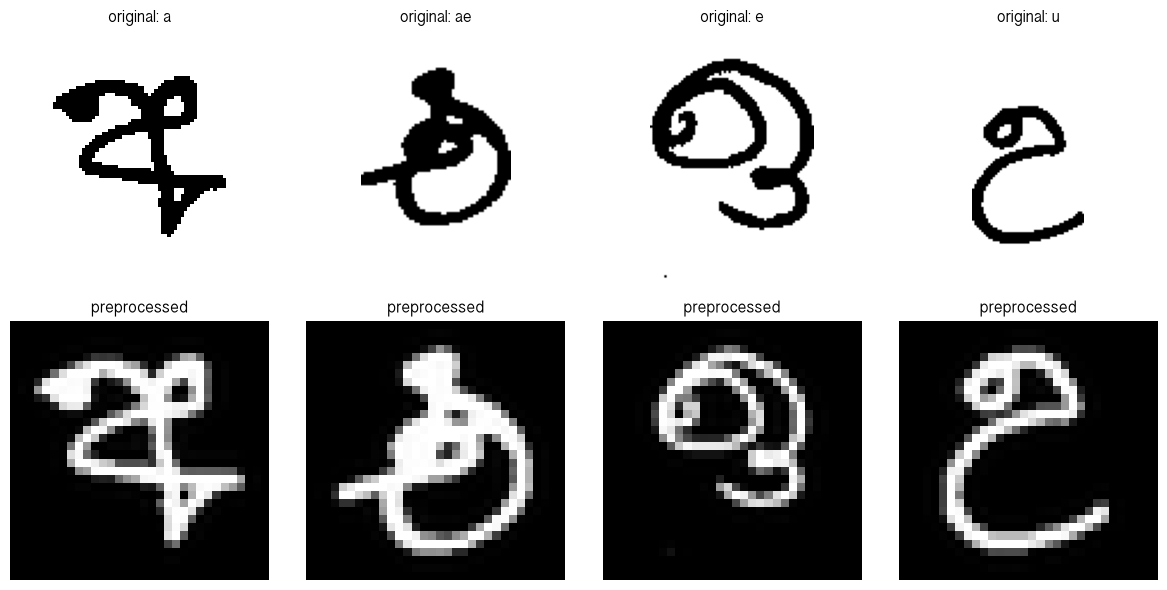

In [11]:
class_dirs= sorted(p for p in DATASET_DIR.iterdir() if p.is_dir() and not p.name.startswith("."))
# print(list(class_dir))

fig , axes = plt.subplots(2 , len(class_dirs) , figsize=(3 * len(class_dirs), 6 ))
axes = np.atleast_2d(axes).reshape(2, -1)



for i, class_dir in enumerate(class_dirs):
    first = next(p for p in sorted(class_dir.iterdir()) if p.suffix.lower() in VALID_EXTENSIONS)
    with Image.open(first) as img:
        axes[0,i].imshow(img.convert("RGB"))
        axes[0,i].set_title(f"original: {class_dir.name}")
        axes[1,i].imshow(preprocess(img).reshape(IMG_SIZE,IMG_SIZE),cmap="gray")
        axes[1,i].set_title("preprocessed") 
    axes[0,i].axis("off")
    axes[1,i].axis("off")
plt.tight_layout()
plt.show()






In [10]:
class EmptyImageError(ValueError):
    """No Letter on the Image"""


def to_gray(img):
    if img.mode in ("RGBA", "LA", "P"):
        img = img.convert("RGBA")
        bg = Image.new("RGBA", img.size, (255, 255, 255, 255))
        img = Image.alpha_composite(bg, img)
    return np.asarray(img.convert("L"), dtype=np.float32)


def ink_on_black(gray):
    border = np.concatenate([gray[0], gray[-1], gray[:, 0], gray[:, -1]])
    return 255.0 - gray if np.median(border) > 127 else gray


def crop_to_letter(gray):
    ys, xs = np.where(gray > INK_THRESHOLD)
    if ys.size == 0:
        raise EmptyImageError("No letter found in image")
    return gray[ys.min(): ys.max() + 1, xs.min(): xs.max() + 1]


def pad_to_square(gray):
    h, w = gray.shape
    side = max(h, w)
    margin = int(side * PADDING_RATIO)
    size = side + 2 * margin
    canvas = np.zeros((size, size), dtype=np.float32)
    top, left = (size - h) // 2, (size - w) // 2
    canvas[top: top + h, left: left + w] = gray
    return canvas


def preprocess(img):
    gray = to_gray(img)
    gray = ink_on_black(gray)
    gray = crop_to_letter(gray)
    gray = pad_to_square(gray)
    small = Image.fromarray(gray.astype(np.uint8)).resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)
    return (np.asarray(small, dtype=np.float32) / 255.0).ravel()

In [25]:
def load_dataset(dataset_dir):
    features , labels , skipped = [],[],0
    class_dirs = sorted(p for p in dataset_dir.iterdir() if p.is_dir() and not p.name.startswith("."))

    for class_dir in class_dirs:
        for path in sorted(class_dir.iterdir()):
            if path.suffix.lower() not in VALID_EXTENSIONS:
                continue
            try:
                with Image.open(path) as img:
                    features.append(preprocess(img))
                labels.append(class_dir.name)
            except(EmptyImageError , OSError) as exc:
                skipped +=1
                print(f"Skipped {path.name} {(exc)}")

    if skipped:
        print(f"{skipped} image skipped")
    if not features:
        raise RuntimeError("No Usable image found")
    return np.vstack(features) , np.array(labels)



X, y = load_dataset(DATASET_DIR)
print("X shape:", X.shape, "| y shape:", y.shape)


counts = Counter(y)
print("Image per letter:",dict(count))
assert len(count)>= 2 ,"Need at least two letters folders"
small = {k: v for k, v in counts.items() if v < MIN_IMAGES_PER_CLASS}
assert not small, f"Too few images(min {MIN_IMAGES_PER_CLASS} per letter): {small}"
    
    
                        

X shape: (192, 1024) | y shape: (192,)
Image per letter: {np.str_('a'): 60, np.str_('ae'): 44, np.str_('e'): 44, np.str_('u'): 44}


In [26]:
x_train , x_test , y_train , y_test = train_test_split(X,y,test_size = TEST_SIZE , stratify=y , random_state = RANDOM_STATE)

print("Train:", x_train.shape , " |Test:" , x_test.shape)



Train: (153, 1024)  |Test: (39, 1024)


In [29]:
#find the best K

search = GridSearchCV(
    KNeighborsClassifier(),
    PARAM_GRID,
    cv=CV_FOLDS,
    scoring="accuracy",
    n_jobs=-1,
)

search.fit(x_train, y_train)

print("Best params:" , search.best_params_)
print(f"CV accuracy : {search.best_score_:.3f}")





Best params: {'n_neighbors': 3, 'weights': 'uniform'}
CV accuracy : 0.973


Test accuracy : 0.974

              precision    recall  f1-score   support

           a       1.00      1.00      1.00        12
          ae       1.00      0.89      0.94         9
           e       0.90      1.00      0.95         9
           u       1.00      1.00      1.00         9

    accuracy                           0.97        39
   macro avg       0.97      0.97      0.97        39
weighted avg       0.98      0.97      0.97        39



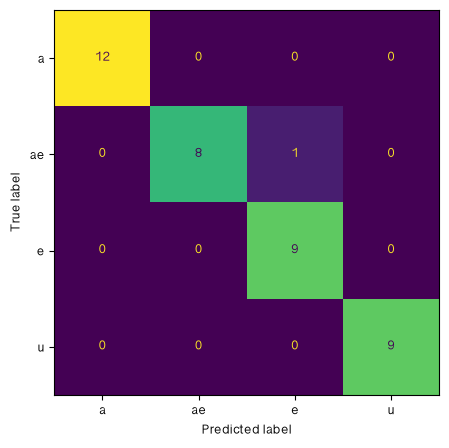

In [37]:
model = search.best_estimator_
predict = model.predict(x_test)
acc = accuracy_score(y_test,predict)

print(f"Test accuracy : {acc:.3f}\n")
print(classification_report(y_test , predict , zero_division=0))

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, predict, ax=ax, colorbar=False)
plt.show()



In [42]:
Model_path = Path("/Users/lasithaakalanka/Desktop/My/python/dataset_sinhala_two/sinhala_letter_model.joblib")

final_model = KNeighborsClassifier(**search.best_params_).fit(X,y)

joblib.dump(
    {
        "model":final_model,
        "labels":list(final_model.classes_),
        "img_size":IMG_SIZE,
        "test_accuracy": acc,
    },
    Model_path
)    

print("Saved" , Model_path.resolve())
                                                            
                                                            
                                           

Saved /Users/lasithaakalanka/Desktop/My/python/dataset_sinhala_two/sinhala_letter_model.joblib


In [ ]:
import tkinter as tk
from tkinter import messagebox
from PIL import ImageDraw, ImageTk

# Folder name (model label) -> Sinhala letter shown on screen.

LABEL_MAP = {"a": "අ", "ae": "එ", "e": "ඉ", "u": "උ"}
CANVAS_SIZE = 300                  # drawing area is 300 x 300 pixels
FONT_NAME = "Sinhala Sangam MN"    # font that can display Sinhala (Mac)


def launch_app(model):
    # ---------- main window ----------
    root = tk.Tk()
    root.title("Sinhala Letter Predictor")
    root.resizable(False, False)   # fixed window size

    # Hidden PIL image: everything drawn on the screen canvas is also drawn
    # here, because a Tkinter canvas cannot be read back as a real image.
    image = Image.new("L", (CANVAS_SIZE, CANVAS_SIZE), 255)   # white background
    draw = ImageDraw.Draw(image)
    state = {"last": None}         # remembers the previous mouse position

    # ---------- widgets ----------
    # Drawing canvas
    canvas = tk.Canvas(root, width=CANVAS_SIZE, height=CANVAS_SIZE, bg="white",
                       cursor="cross", highlightthickness=1, highlightbackground="#888")
    canvas.grid(row=0, column=0, columnspan=2, padx=12, pady=12)

    # Brush size slider (match it to the stroke thickness in the dataset images)
    tk.Label(root, text="Brush size").grid(row=1, column=0, sticky="e")
    brush = tk.Scale(root, from_=4, to=30, orient="horizontal")
    brush.set(14)                  # default brush size
    brush.grid(row=1, column=1, sticky="we", padx=8)

    # Large label that shows the predicted Sinhala letter
    result = tk.Label(root, text="", font=(FONT_NAME, 64))
    result.grid(row=3, column=0, columnspan=2)

    # Text that shows the top 3 guesses with their percentages
    detail = tk.Label(root, text="Draw a letter, then press Predict", justify="left")
    detail.grid(row=4, column=0, columnspan=2, padx=12)

    # Preview of the 32x32 image the model actually receives
    tk.Label(root, text="What the model sees (32x32):").grid(row=5, column=0, columnspan=2, pady=(10, 0))
    preview = tk.Label(root)
    preview.grid(row=6, column=0, columnspan=2, pady=(0, 12))

    # ---------- drawing ----------
    def on_move(e):
        # Runs while the mouse moves with the left button held down
        w = brush.get()                        # current brush size
        if state["last"]:                      # skip the very first point
            x0, y0 = state["last"]
            # Draw the line on the screen canvas (for the user to see)
            canvas.create_line(x0, y0, e.x, e.y, width=w, capstyle="round", fill="black")
            # Draw the same line on the hidden image (for the model)
            draw.line([x0, y0, e.x, e.y], fill=0, width=w)
            # Round dot at the current point so joints have no gaps
            r = w / 2
            draw.ellipse([e.x - r, e.y - r, e.x + r, e.y + r], fill=0)
        state["last"] = (e.x, e.y)             # remember this point for next time

    def on_release(e):
        # Mouse button released: forget the last point, so the next stroke
        # does not connect to the previous one
        state["last"] = None

    def on_clear():
        # Erase the screen canvas and the hidden image, and reset the labels
        canvas.delete("all")
        draw.rectangle([0, 0, CANVAS_SIZE, CANVAS_SIZE], fill=255)
        result.config(text="")
        detail.config(text="Draw a letter, then press Predict")
        preview.config(image="")

    # ---------- predicting ----------
    def on_predict(event=None):
        # event=None lets this work from both the button and the Enter key
        try:
            # Same preprocessing as the training images: grayscale, invert,
            # crop, square, resize to 32x32, flatten to 1024 numbers
            vec = preprocess(image)
        except EmptyImageError:
            # Nothing was drawn on the canvas
            messagebox.showinfo("Nothing drawn", "Please draw a letter first.")
            return

        # Probability for each letter (the model expects a 2D array: 1 row)
        proba = model.predict_proba(vec.reshape(1, -1))[0]
        # Indexes of the 3 highest probabilities, best first
        order = np.argsort(proba)[::-1][:3]
        # List of (letter label, probability) for the top 3
        top = [(str(model.classes_[i]), proba[i]) for i in order]

        # Show the best guess as a large Sinhala letter
        result.config(text=LABEL_MAP.get(top[0][0], top[0][0]))
        # Show the top 3 guesses with percentages, one per line
        detail.config(text="\n".join(
            f"{LABEL_MAP.get(l, l)}  ({l}):  {p * 100:.0f}%" for l, p in top))

        # Show the 32x32 image the model saw, enlarged 4x so it is clear
        small = Image.fromarray((vec.reshape(IMG_SIZE, IMG_SIZE) * 255).astype(np.uint8))
        photo = ImageTk.PhotoImage(small.resize((IMG_SIZE * 4, IMG_SIZE * 4), Image.NEAREST))
        preview.config(image=photo)
        preview.image = photo      # keep a reference, otherwise Python deletes the image

    # ---------- buttons ----------
    tk.Button(root, text="Predict", width=12, command=on_predict).grid(row=2, column=0, pady=8)
    tk.Button(root, text="Clear", width=12, command=on_clear).grid(row=2, column=1, pady=8)

    # ---------- connect mouse and keyboard events ----------
    canvas.bind("<B1-Motion>", on_move)            # drag with left button: draw
    canvas.bind("<ButtonRelease-1>", on_release)   # release: end of stroke
    root.bind("<Return>", on_predict)              # Enter key = Predict

    # ---------- Mac: keep the window in front of the browser ----------
    root.lift()
    root.attributes("-topmost", True)
    root.after(300, lambda: root.attributes("-topmost", False))   # turn off after 0.3 s
    root.protocol("WM_DELETE_WINDOW", root.destroy)               # close button closes the window

    # Keep the window open and handle events until it is closed
    root.mainloop()


# Start the app with the trained model loaded earlier in the notebook
launch_app(final_model)